# 3 · Motion, not pixels

Notebook 2's network was asked for pixels and learned to blur: on a scrolled page it gained
1.3 dB where notebook 1's tile shift - a search, no training - gained 11.2. The shift wins
because it *copies*: a correct offset moves the content exactly. So here the output is
motion, and `current` is moved by it (`models.warp`, a `GridSample` in the graph):

- **learned motion**: notebook 2's encoder with a head that makes an offset per pixel
  instead of a correction to the picture. Starts as repeat (offset zero).
- **tile search**: notebook 1's tile shift rebuilt from fixed convolutions, so a graph can
  hold it (`models.TileSearch`): the cost of every offset within ±8 px, computed on luma at
  half the resolution, averaged over the tile, and a softmax over the costs to pick one
  motion. Nothing in it learns.
- **search + correction**: the tile search, and the learned head adding a correction per
  pixel on top - for what one motion a tile cannot follow: a cursor, a dragged window, a
  region scrolling. Starts as the tile search.

And `models.Gate`, the rule a client can apply per tile before running anything: where
nothing moved between `previous` and `current`, repeat.

Steps:

1. **Data** - as notebook 2: halo 8, and the client's 4.
2. **Models** - built, and checked to start where they should.
3. **The tile search** - untrained: how sharp, and at the client's halo.
4. **Speed** - torch, and the graph at the client's tile.
5. **Train** - the two learned models.
6. **Results** - against repeat, notebook 1's exact shift and notebook 2's network, gated
   and not; and what it looks like.
7. **Export** - the best graph that needs no training goes to `dist/`.

Needs: `00_data_preprocess.ipynb`, and `02_extrapolate_twoscale.ipynb` for its checkpoint.
Results: `summary.md`, "Motion".

In [1]:
"""Settings."""

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import metrics, models, runs, speed, training, webexport
from helpers.training import DATA_DIR, DEVICE

RUN_DIR = training.CHECKPOINT_DIR / "motion_runs"       # each training, resumable
TWOSCALE = training.CHECKPOINT_DIR / "extrapolate_twoscale.pt"   # notebook 2's network

WIDTHS, BLOCKS = (16, 32), 3     # the learned head: notebook 2's encoder
RADIUS = 4                       # the search: offsets within ±RADIUS at half resolution = ±8 px
SCALE = 2
SHARPNESS = 10.0                 # chosen in "3. The tile search"
STRIDE = 2                       # the cost sampled on every 2nd position: chosen in "4. Speed"
STILL = 0.1                      # the published search's own gate, in luma levels: see "6. Results"

HALO = 8
CONTEXT, AHEAD = 2, 1
BATCH_SIZE = 64
LEARNING_RATE = 1e-4             # offsets in pixels: 1e-3 moves them too far a step
MAX_EPOCHS = 500                 # a safety limit; training stops once it has converged
SEED = 0

BENCH_SIZES = [(640, 360), (960, 540), (1280, 720), (1920, 1080)]
training.seed_everything(SEED)

## 1. Data

The same samples as notebook 2, so every number below compares with its tables.

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
train_loader = training.loader(DATA_DIR, manifest, BATCH_SIZE, CONTEXT, AHEAD, halo=HALO)

validation = {}
for halo in sorted({HALO, webexport.TILE_HALO}):
    inputs, targets = runs.load(DATA_DIR, "val", manifest, CONTEXT, AHEAD, halo=halo)
    masks = runs.groups(manifest, "val", inputs[:, -1], targets, halo)
    validation[halo] = (inputs, targets, masks)
KINDS = [kind for kind in ("page", "desktop", "photo", "video", "cursor") if kind in masks]
for halo, (_, _, masks) in validation.items():
    for kind in KINDS:
        masks[f"{kind}, changed"] = masks[kind] & masks["changed"]
inputs, targets, masks = validation[HALO]
STEP = runs.received_every(manifest)   # received frames N-2 and N in, N+1 out
FRACTION = AHEAD / STEP                # the search carries half the motion it finds between them
print("val    ", inputs.shape, "->", targets.shape)

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)
train  11445 runs from 748 sources


val     (1677, 2, 80, 80, 3) -> (1677, 80, 80, 3)


## 2. Models

    learned motion        previous, current --> encoder (notebook 2) --> head --> offset per pixel
    tile search           previous, current --> luma at 1/2 --> |current - previous moved by d|, 81 offsets
                                                --> mean over the tile --> softmax --> one offset
    search + correction   tile search offset + learned offset per pixel
    then                  current --> GridSample at every pixel + its offset --> output

The search's cost is fixed convolutions and a few elementwise operators: luma of each frame
at half the resolution (a 2x2 stride-2 `Conv`), `previous` moved by every offset (one `Conv`
from 1 channel to 81, each kernel a single 1) and `current` at the kernels' centre, both
without padding so only positions where every offset reads inside the picture count, then
`Sub`, `Abs` and the mean over the tile (`ReduceMean`). `STRIDE` samples those positions on
a coarser grid - a mean needs a few thousand of them, not all.

**How each works, and whether it learns.** In all three the picture is made the same way:
`GridSample` reads `current` where the motion points, so a pixel of N+1 is always a pixel
of N, moved. What differs is where the motion comes from:

| | where the motion comes from | learns? |
| --- | --- | --- |
| learned motion | a network - notebook 2's encoder and a head - outputs an (x, y) offset for every pixel | yes, all of it: every weight fitted by Adam |
| tile search | the cost of 81 candidate motions, averaged over the tile; a softmax weighs them and their weighted mean is one motion for the tile | no: every weight is set by hand - luma coefficients, kernels that are a single 1 - and sharpness and stride were chosen by measuring them below |
| search + correction | the tile search's motion plus the network's correction per pixel | only the correction; the search stays fixed |
| `Gate` | a rule: repeat where under 0.5% of the pixels changed by more than 8 luma levels | no |
| the search's own gate (`still`) | a rule: no motion where the tile's cost at no motion is under 0.1 luma levels | no |

So the published model learns nothing. Its numbers were *chosen* - by scoring a few values on
the validation samples - but no weight was trained.

In [3]:
def search():
    return models.TileSearch(RADIUS, SCALE, SHARPNESS, STRIDE, FRACTION)


builders = {
    "learned motion": lambda: models.Motion(WIDTHS, BLOCKS),
    "tile search": lambda: models.Motion(search=search(), learned=False),
    "search + correction": lambda: models.Motion(WIDTHS, BLOCKS, search=search()),
}
networks = {name: build().to(DEVICE) for name, build in builders.items()}
for name, network in networks.items():
    learned = sum(p.numel() for p in network.parameters() if p.requires_grad)
    print(f"{name:20} {learned:7,} learned parameters, {speed.operations_per_pixel(network):7,.0f} operations a pixel")

# notebook 2's network, for the tables
checkpoint = training.load_checkpoint(TWOSCALE)
twoscale = models.TwoScale(**checkpoint["arguments"]).to(DEVICE)
twoscale.load_state_dict(checkpoint["state_dict"])

learned motion        35,000 learned parameters,   5,342 operations a pixel
tile search                0 learned parameters,     479 operations a pixel
search + correction   35,000 learned parameters,   5,821 operations a pixel


<All keys matched successfully>

In [4]:
"""Before training: learned motion is repeat, and search + correction is the tile search."""

start = {name: training.evaluate(network, inputs, targets, masks, trim=HALO)
         for name, network in networks.items()}
repeat = training.evaluate(models.Repeat(), inputs, targets, masks, trim=HALO)
assert abs(start["learned motion"]["all"]["rgb"] - repeat["all"]["rgb"]) < 1e-3
assert abs(start["search + correction"]["all"]["rgb"] - start["tile search"]["all"]["rgb"]) < 1e-3
metrics.print_table({"repeat": repeat["changed"], **{name: scores["changed"] for name, scores in start.items()}})

                         wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                   25.69    24.50    62.00    62.61     24.31   0.7040
learned motion           25.69    24.50    62.00    62.61     24.31   0.7040
tile search              36.78    35.84    65.78    66.27     35.06   0.8604
search + correction      36.78    35.84    65.78    66.27     35.06   0.8604


## 3. The tile search

The search needs no training, but it has a setting: `sharpness`, how hard the softmax
picks the cheapest offset. Soft, it averages neighbouring offsets, which lands between
pixels and blurs; hard, it is notebook 1's argmin. And a radius: ±8 px needs a halo of 8,
and the client's tiles have 4 - so the same search is scored there too, where offsets past
4 read the edge repeated.

In [5]:
"""Sharpness and stride, at a halo of 8; then radius at the client's halo of 4."""

shown = ["changed", *[f"{kind}, changed" for kind in KINDS], "unchanged"]
print(f"{'wPSNR (dB)':<22}" + "".join(f"{name.split(',')[0]:>10}" for name in shown))
for sharpness, stride in ((3, 1), (10, 1), (30, 1), (10, 2), (10, 4)):
    scores = training.evaluate(models.Motion(search=models.TileSearch(RADIUS, SCALE, sharpness, stride, FRACTION), learned=False),
                               inputs, targets, masks, trim=HALO)
    print(f"{f'sharpness {sharpness}, stride {stride}':<22}" + "".join(f"{scores[name]['wpsnr']:10.2f}" for name in shown))
exact = training.evaluate(models.Shift(radius=HALO, block=None, fraction=FRACTION), inputs, targets, masks, trim=HALO)
print(f"{'exact shift (nb 1)':<22}" + "".join(f"{exact[name]['wpsnr']:10.2f}" for name in shown))

x4, y4, masks4 = validation[webexport.TILE_HALO]
print(f"\nat the client's halo of {webexport.TILE_HALO}, changed samples")
for radius in (2, 4):
    scores = training.evaluate(models.Motion(search=models.TileSearch(radius, SCALE, SHARPNESS, STRIDE, FRACTION), learned=False),
                               x4, y4, masks4, trim=webexport.TILE_HALO)["changed"]
    print(f"  search ±{SCALE * radius} px: {scores['wpsnr']:.2f} dB, {scores['ssim']:.4f} SSIM-Y")
scores = training.evaluate(models.Shift(radius=webexport.TILE_HALO, block=None, fraction=FRACTION), x4, y4, masks4, trim=webexport.TILE_HALO)["changed"]
print(f"  exact shift ±{webexport.TILE_HALO} px (nb 1): {scores['wpsnr']:.2f} dB, {scores['ssim']:.4f} SSIM-Y")

wPSNR (dB)               changed      page   desktop     photo     video    cursor unchanged


sharpness 3, stride 1      36.39     36.30     27.21     37.95     37.62     30.67     77.20


sharpness 10, stride 1     36.71     37.20     27.16     37.70     37.46     31.45     82.22


sharpness 30, stride 1     36.69     37.35     27.16     37.49     37.35     31.41     83.33


sharpness 10, stride 2     36.78     37.46     27.08     37.61     37.40     32.35     81.12


sharpness 10, stride 4     35.87     35.67     26.17     37.57     37.42     30.41     77.34


exact shift (nb 1)         35.96     36.64     27.27     36.33     37.23     30.78     83.68

at the client's halo of 4, changed samples


  search ±4 px: 34.88 dB, 0.8211 SSIM-Y


  search ±8 px: 36.42 dB, 0.8593 SSIM-Y


  exact shift ±4 px (nb 1): 34.82 dB, 0.8261 SSIM-Y


## 4. Speed

In torch on this computer's GPU, one stream frame - where the search finds one motion for
the whole frame, not per tile, so it is only a cost. Then the graph the client would run, at
its 328x188 tile, on the desktop CPU.

**In the browser** (`../upscale/benchmark/main.py --models <folder>`, which feeds every input
a graph has; Chrome 156 headless, WebGPU, RTX 3090, GPU-resident tensors, the output buffer
reused; GPU time from timestamp queries), one 1080p stream frame - 36 tiles in one batch:

| graph | GPU ms a 1080p frame |
| --- | --- |
| linear (the mock) | 0.25 |
| two-scale network (notebook 2) | 3.6 |
| tile search, the first form (a 162-channel 9x9 `Conv` of two taps each) | 13.9 |
| tile search, stride 1 | 5.7 |
| **tile search, stride 2** | **2.2-2.4** |
| tile search, stride 4 | 1.4 |
| tile search + correction, the first form | 16.8 |

Every operator ran on the GPU, `GridSample` included - wall clock and GPU time agree. The
first form spent its time on a dense convolution whose kernels were 2 taps in 81; moving
`previous` with one 1-to-81 `Conv` and subtracting is the same arithmetic for a quarter of
the work, and a stride of 2 a quarter again. Stride 2 is chosen: under notebook 2's network
in time, and 0.2 dB under stride 1 on these 80 px samples, whose inner tile has 16x16
positions at stride 2 - the client's 328x188 tile has 78x43.

In [6]:
print(f"{'frame':>11}" + "".join(f"{name:>22}" for name in networks))
with torch.no_grad():
    for width, height in BENCH_SIZES:
        previous, current = torch.rand(2, 1, 3, height, width, device=DEVICE)
        row = [speed.time_ms(lambda n=network: n.eval()(previous, current), seconds=0.5) for network in networks.values()]
        print(f"{f'{width}x{height}':>11}" + "".join(f"{ms:22.2f}" for ms in row))
print("ms per frame")

for name, network in networks.items():
    info = webexport.export(network, f"speed_check_{name.replace(' ', '_').replace('+', 'and')}.onnx",
                            webexport.TILE_INPUT, models_dir=training.CHECKPOINT_DIR / "speed")
    print(webexport.summary_line(info, webexport.time_graph(info["path"], webexport.TILE_INPUT)))

      frame        learned motion           tile search   search + correction


    640x360                  0.52                  0.36                  0.73


    960x540                  0.60                  0.36                  0.84


   1280x720                  1.05                  0.49                  1.41


  1920x1080                  2.32                  1.03                  3.07
ms per frame


speed_check_learned_motion.onnx                       144.0 KB    2.36 ms   Addx4, Concatx3, Constantx14, Convx6, DepthToSpacex2, Gatherx2, GridSamplex1, LeakyRelux5, Mulx4, Reciprocalx2, Subx2, Unsqueezex2   OUTSIDE BUDGET: Gather, GridSample, Mul, Reciprocal, Sub, Unsqueeze


speed_check_tile_search.onnx                           34.0 KB    1.39 ms   Absx1, Addx4, Concatx1, Constantx21, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx2, GridSamplex1, MatMulx1, Mulx7, Reciprocalx2, ReduceMeanx1, Softmaxx1, Subx3, Unsqueezex4, Wherex1   OUTSIDE BUDGET: Abs, ConstantOfShape, Equal, Expand, Gather, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Softmax, Sub, Unsqueeze, Where


speed_check_search_and_correction.onnx                172.8 KB    2.39 ms   Absx1, Addx5, Concatx3, Constantx18, Convx10, DepthToSpacex2, Gatherx2, GridSamplex1, LeakyRelux5, MatMulx1, Mulx6, Reciprocalx2, ReduceMeanx1, Softmaxx1, Subx3, Unsqueezex4   OUTSIDE BUDGET: Abs, Gather, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Softmax, Sub, Unsqueeze


## 5. Train

The two learned models, with the loss of notebook 2 (`metrics.luma_chroma_l1`) on the
picture the warp makes. The epoch kept is the one with the best **wPSNR** on the changed
samples, not SSIM as in notebook 2: a warp that drifts a fraction of a pixel blurs, and in
the prototypes SSIM-Y barely moved while wPSNR on scrolled pages fell by 5 dB. The learning
rate is 1e-4: at 1e-3 every step moves the offsets of every pixel a visible fraction of a
pixel.

Search + correction starts as the tile search, so its untrained score is the bar: if no
epoch beats it, the correction has learned nothing worth keeping, and `train` says so.


learned motion


Loaded the training saved in /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/motion_runs/learned_motion_halo8.pt: 188 epochs done in 6.7 min, best epoch 158 (val_changed_wpsnr: 27.6965), learning rate now 1.0e-06.
It had finished (converged - no improvement in 6 epochs, even at the smallest learning rate), so nothing is trained again - delete the file to train from the start.
Restoring model weights from the end of the best epoch: 158 (val_changed_wpsnr: 27.6965, +2.0056 over repeat). Training took 188 epochs, 6.7 min.

search + correction
Loaded the training saved in /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/motion_runs/search_and_correction_halo8.pt: 48 epochs done in 103s, best epoch 0 (val_changed_wpsnr: 36.7816), learning rate now 1.0e-06.
It had finished (converged - no improvement in 6 epochs, even at the smallest learning rate), so nothing is trained again - delete the file to train from the start.
Restoring model weights from the end of 

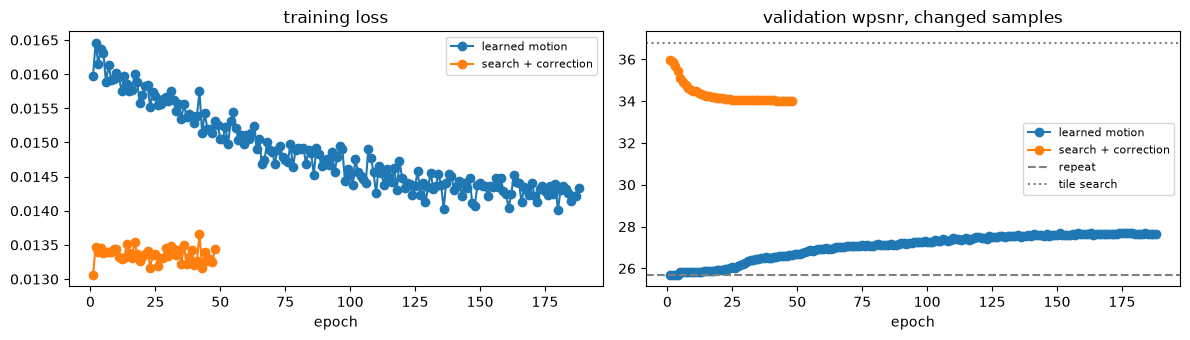

In [7]:
histories, bests = {}, {}
for name in ("learned motion", "search + correction"):
    print(f"\n{'=' * 100}\n{name}\n{'=' * 100}")
    training.seed_everything(SEED)
    histories[name], bests[name] = training.train(
        networks[name], train_loader, validation[HALO], HALO, MAX_EPOCHS, learning_rate=LEARNING_RATE,
        select=("changed", "wpsnr"), checkpoint=RUN_DIR / f"{name.replace(' ', '_').replace('+', 'and')}_halo{HALO}.pt")
training.plot_history(histories, {"repeat": repeat, "tile search": start["tile search"]}, key="wpsnr")

## 6. Results

Every model, ungated and gated: by group, by kind of source, and at the client's halo.

Two gates. `models.Gate` compares every pixel of the two frames, as the run set defines a
change. The search has a cheaper one of its own: its cost at no motion *is* the mean luma
difference between the two frames over the tile, so `TileSearch(still=...)` sets the motion to
zero under that many luma levels, and a zero motion hands `current` back as it is. In the
browser the first costs 2 ms of GPU and 5.5 ms of wall clock a 1080p frame - as much as the
search - and the second nothing measurable. `STILL` = 0.1 levels, the frames all but equal,
scores like `Gate` (a sweep of 0.1-1.0 moved the changed samples by 0.1 dB and the unchanged
ones by 0.2).

In [8]:
contenders = {"repeat": models.Repeat(), "linear (mock)": models.Blend(1.0),
              "exact shift (nb 1)": models.Shift(radius=HALO, block=None, fraction=FRACTION),
              "two-scale (nb 2)": twoscale, **networks}
results = {name: training.evaluate(model, inputs, targets, masks, trim=HALO) for name, model in contenders.items()}
for name in ("two-scale (nb 2)", "tile search", "search + correction"):
    results[f"{name}, gated"] = training.evaluate(models.Gate(contenders[name]), inputs, targets, masks, trim=HALO)
# the search's own gate: its cost at no motion is how much the tile changed, so under STILL
# the motion is set to zero - two numbers a tile, against Gate's pass over every pixel
published = models.Motion(search=models.TileSearch(RADIUS, SCALE, SHARPNESS, STRIDE, FRACTION, still=STILL), learned=False)
results[f"tile search, own gate ({STILL})"] = training.evaluate(published, inputs, targets, masks, trim=HALO)

for group in ("changed", "unchanged", "all"):
    print(f"\n{group}: {masks[group].sum()} samples, halo {HALO}")
    metrics.print_table({name: scores[group] for name, scores in results.items()},
                        extra=lambda name, s, g=group: f"   {s['wpsnr'] - results['repeat'][g]['wpsnr']:+6.2f} dB vs repeat")


changed: 749 samples, halo 8
                                 wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                           25.69    24.50    62.00    62.61     24.31   0.7040    +0.00 dB vs repeat
linear (mock)                    21.94    20.75    58.29    58.72     20.60   0.6326    -3.75 dB vs repeat
exact shift (nb 1)               35.96    35.01    65.82    66.29     34.28   0.8657   +10.27 dB vs repeat
two-scale (nb 2)                 26.60    25.42    58.94    60.70     25.20   0.7340    +0.91 dB vs repeat
learned motion                   27.70    26.50    62.91    63.53     26.32   0.7753    +2.01 dB vs repeat
tile search                      36.78    35.84    65.78    66.27     35.06   0.8604   +11.09 dB vs repeat
search + correction              36.78    35.84    65.78    66.27     35.06   0.8604   +11.09 dB vs repeat
two-scale (nb 2), gated          26.60    25.42    59.02    60.73     25.20   0.7340    +0.91 dB vs repeat
tile search, gated           

In [9]:
"""By kind of source (changed samples); and the models at the client's halo."""

for key, label, digits in (("ssim", "SSIM-Y", 4), ("wpsnr", "wPSNR (dB)", 2)):
    print(f"{label + ', changed':<28}" + "".join(f"{kind:>10}" for kind in KINDS))
    for name, scores in results.items():
        if "gated" in name:
            continue
        print(f"{name:<28}" + "".join(f"{scores[f'{kind}, changed'][key]:10.{digits}f}" for kind in KINDS))
    print()

small = webexport.TILE_HALO
print(f"{'changed samples':<28}{f'halo {HALO}':>18}{f'halo {small}':>18}")
print(f"{'':<28}" + f"{'SSIM-Y':>9}{'wPSNR':>9}" * 2)
for name in ("repeat", "exact shift (nb 1)", "two-scale (nb 2)", *networks):
    model = models.Shift(radius=small, block=None, fraction=FRACTION) if name == "exact shift (nb 1)" else contenders[name]
    narrow = training.evaluate(model, x4, y4, masks4, trim=small)["changed"]
    wide = results[name]["changed"]
    print(f"{name:<28}{wide['ssim']:9.4f}{wide['wpsnr']:9.2f}{narrow['ssim']:9.4f}{narrow['wpsnr']:9.2f}")

SSIM-Y, changed                   page   desktop     photo     video    cursor
repeat                          0.6723    0.7668    0.6462    0.9277    0.7170
linear (mock)                   0.6185    0.7154    0.5355    0.8823    0.6537
exact shift (nb 1)              0.8167    0.7650    0.9194    0.9574    0.8006
two-scale (nb 2)                0.6873    0.7672    0.7120    0.9364    0.7387
learned motion                  0.7421    0.7769    0.7577    0.9362    0.7635
tile search                     0.8083    0.7633    0.9157    0.9574    0.7890
search + correction             0.8083    0.7633    0.9157    0.9574    0.7890
tile search, own gate (0.1)     0.8083    0.7633    0.9157    0.9574    0.7889

wPSNR (dB), changed               page   desktop     photo     video    cursor
repeat                           23.49     25.94     25.04     34.98     26.15
linear (mock)                    19.77     23.06     21.00     31.40     22.25
exact shift (nb 1)               36.64     27.27   

repeat                         0.7040    25.69   0.7040    25.69


exact shift (nb 1)             0.8657    35.96   0.8261    34.82


two-scale (nb 2)               0.7340    26.60   0.7335    26.57


learned motion                 0.7753    27.70   0.7733    27.39


tile search                    0.8604    36.78   0.8593    36.42


search + correction            0.8604    36.78   0.8593    36.42


### What it looks like

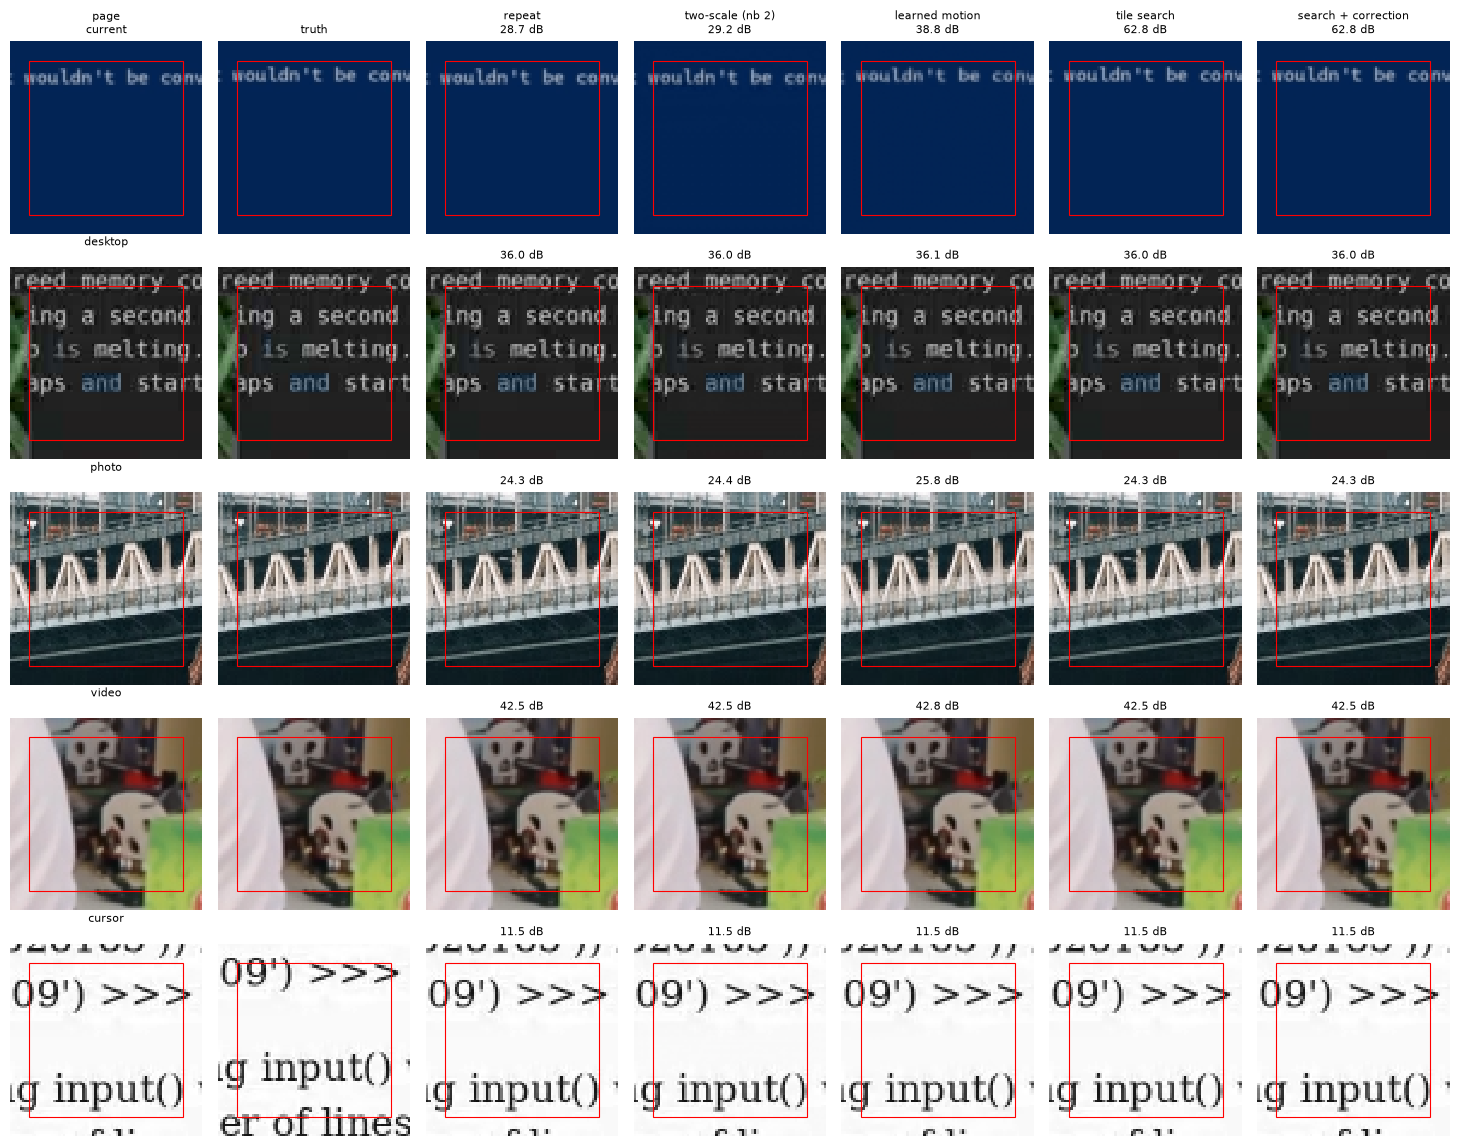

In [10]:
pick_rng = np.random.default_rng(SEED)
picks = [(kind, int(pick_rng.choice(np.flatnonzero(masks[f"{kind}, changed"]))))
         for kind in KINDS if masks[f"{kind}, changed"].any()]
shown_models = {"repeat": models.Repeat(), "two-scale (nb 2)": twoscale.eval(),
                **{name: network.eval() for name, network in networks.items()}}

columns = ["current", "truth", *shown_models]
fig, axes = plt.subplots(len(picks), len(columns), figsize=(2.1 * len(columns), 2.3 * len(picks)), squeeze=False)
for row, (kind, index) in enumerate(picks):
    sample = training.to_tensor(inputs[index:index + 1])
    truth = training.to_tensor(targets[index:index + 1])
    pictures = {"current": sample[:, 1], "truth": truth}
    with torch.no_grad():
        for name, model in shown_models.items():
            pictures[name] = model(sample[:, 0], sample[:, 1]).clamp(0, 1)
    for column, name in enumerate(columns):
        ax = axes[row][column]
        ax.imshow(pictures[name][0].permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
        ax.add_patch(plt.Rectangle((HALO - 0.5, HALO - 0.5), manifest["core"], manifest["core"],
                                   fill=False, color="red", lw=0.8))
        title = name if row == 0 else ""
        if name in shown_models:
            score = metrics.wpsnr(runs.trim(pictures[name], HALO), runs.trim(truth, HALO))
            title = f"{title}\n{score:.1f} dB" if title else f"{score:.1f} dB"
        if column == 0:
            title = f"{kind}\n{title}"
        ax.set_title(title, fontsize=8)
        ax.axis("off")
fig.tight_layout()
plt.show()

### How the search decides

For one changed page, photo and desktop sample whose content really moves: the search's cost of each of the 81 motions
it tries - the mean luma difference between N and N-2 moved that far, over the whole tile;
dark is a good match - then the softmax weights those costs get at a sharpness of 10, and
the one motion their weighted mean makes (the red cross on both). Next to it, the motion
the search carries to N+1 (yellow, twice its length) and the motion that really happened
between N and N+1 (green: a block search between N and the true N+1, which sees the answer).
A scroll has one deep minimum; where two neighbouring motions match about as well, as on the
photo, the softmax splits its weight between them and lands between whole pixels; a desktop
where only a corner moved has its minimum at no motion, and the search leaves the tile where
it is.

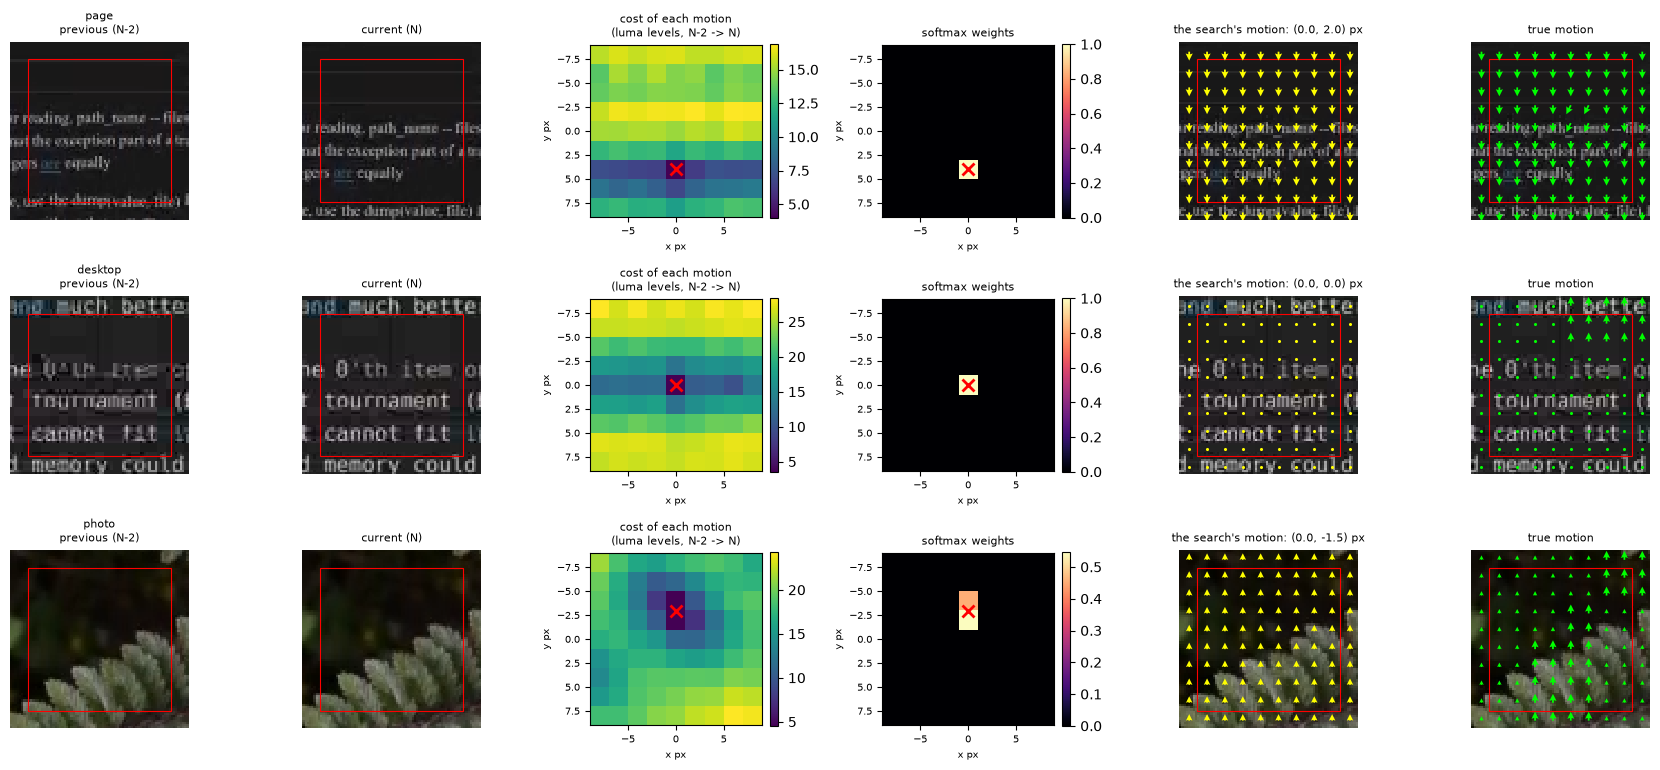

In [10]:
"""Inside the tile search, for one changed sample of three kinds."""

from helpers import show

box = (HALO, HALO, manifest["core"], manifest["core"])
tile_search = search().to(DEVICE).eval()
reference = models.Shift(radius=HALO, block=16, fraction=1.0).to(DEVICE)   # N -> the true N+1: sees the answer
offsets = [(dy, dx) for dy in range(-RADIUS, RADIUS + 1) for dx in range(-RADIUS, RADIUS + 1)]
grid = SCALE * torch.tensor([(dx, dy) for dy, dx in offsets], dtype=torch.float32, device=DEVICE)   # each motion, (x, y) px
moving = show.moving_picks(inputs, targets, masks, KINDS, HALO, seed=SEED)   # changed samples whose content really moves
shown_picks = [(kind, index) for kind, index in moving if kind in ("page", "photo", "desktop")]
columns = ["previous (N-2)", "current (N)", "cost of each motion", "softmax weights", "the search's motion", "true motion"]
fig, axes = plt.subplots(len(shown_picks), len(columns), figsize=(2.8 * len(columns), 2.6 * len(shown_picks)),
                         squeeze=False)
for row, (kind, index) in enumerate(shown_picks):
    previous, current = training.to_tensor(inputs[index:index + 1]).unbind(1)
    truth = training.to_tensor(targets[index:index + 1])
    with torch.no_grad():
        cost = tile_search.costs(previous, current)[0]
        weights = torch.softmax(-SHARPNESS * cost, dim=0)
        settled = (weights @ grid).tolist()        # the motion from N-2 to N it settles on
        field = tile_search(previous, current).expand(-1, -1, *current.shape[-2:])
        true_motion = reference.field(current, truth)
    ax = axes[row]
    show.picture(ax[0], previous, f"{kind}\n{columns[0]}", box)
    show.picture(ax[1], current, columns[1], box)
    show.offset_map(ax[2], cost, RADIUS, SCALE, f"{columns[2]}\n(luma levels, N-2 -> N)", mark=settled)
    show.offset_map(ax[3], weights, RADIUS, SCALE, columns[3], cmap="magma", mark=settled)
    show.motion(ax[4], current, field, f"{columns[4]}: ({0.0 - field[0, 0, 0, 0]:.1f}, {0.0 - field[0, 1, 0, 0]:.1f}) px", box)
    show.motion(ax[5], current, true_motion, columns[5], box, colour=show.TRUE)
fig.tight_layout()
plt.show()

### The motion each model found

One changed sample of each kind whose content really moves, with the motion each model carries to N+1 (yellow, twice its
length) beside the true one (green), and where its picture is wrong. The learned motion
hardly moves anything - mostly dots, a few short arrows where it is sure: per pixel it cannot
tell which way a line of text went, and a short motion, or none, is its hedge. The search has one arrow for the whole tile.

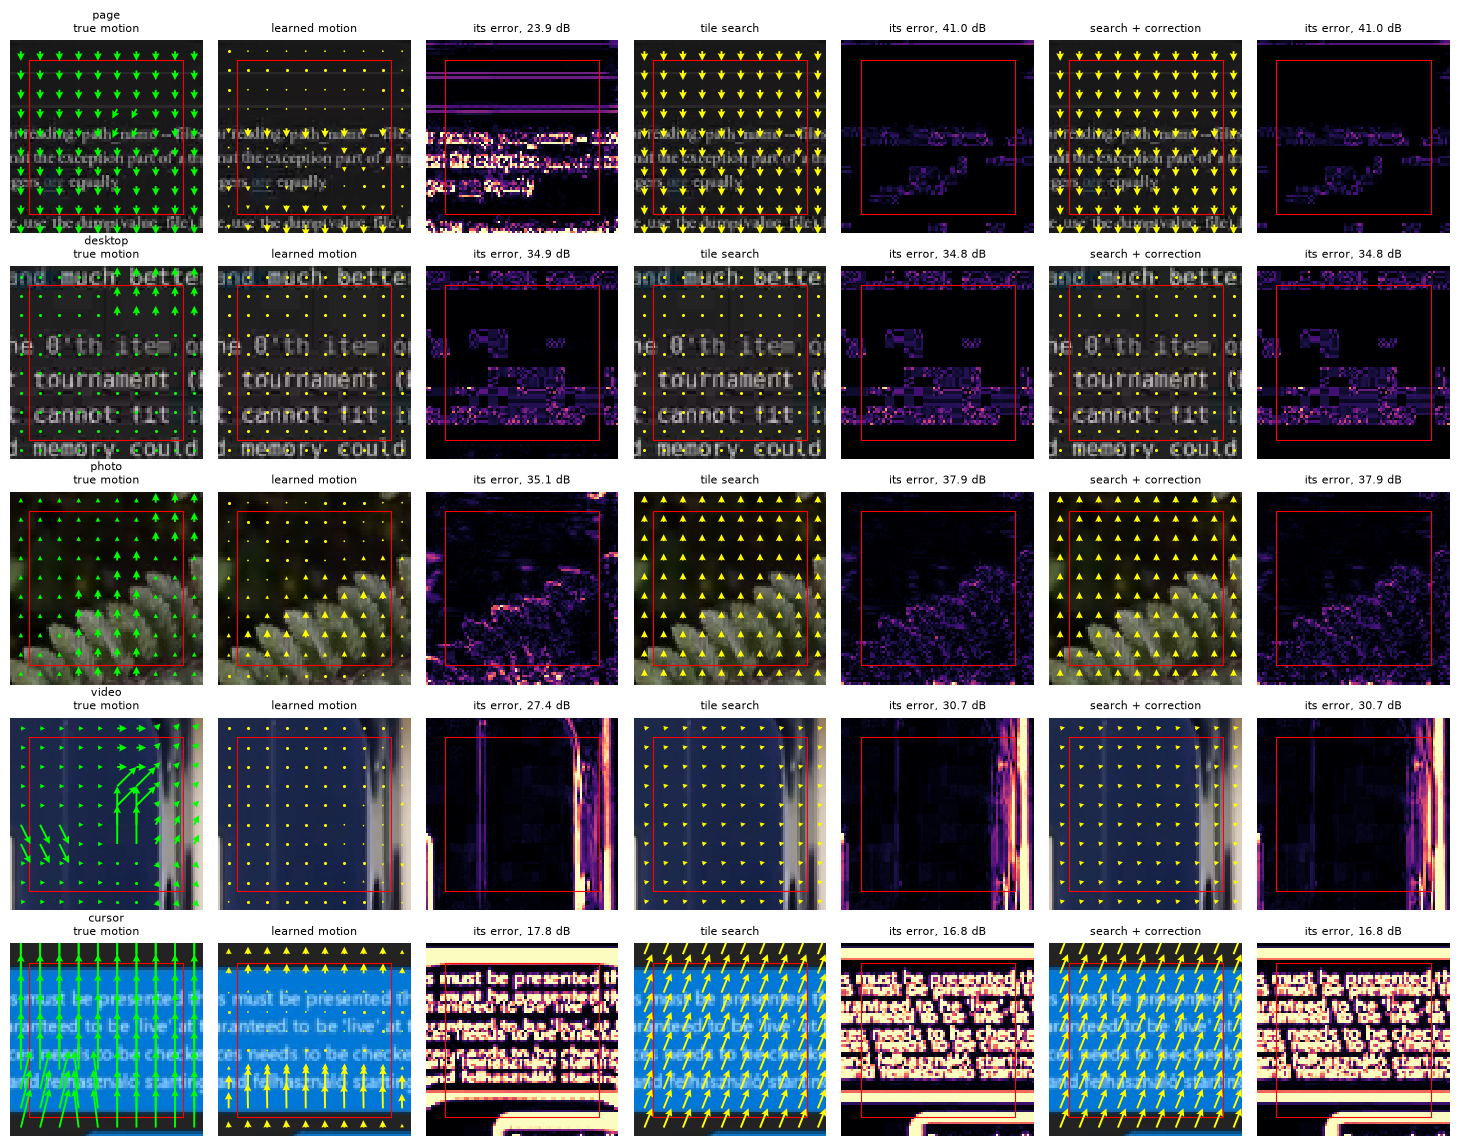

arrows twice their length; errors full colour at 48 luma levels


In [11]:
"""The motion each model found, against the motion that really happened."""

motion_models = {name: networks[name].eval() for name in ("learned motion", "tile search", "search + correction")}
columns = ["true motion", *[label for name in motion_models for label in (name, "its error")]]
fig, axes = plt.subplots(len(moving), len(columns), figsize=(2.1 * len(columns), 2.3 * len(moving)), squeeze=False)
for row, (kind, index) in enumerate(moving):
    previous, current = training.to_tensor(inputs[index:index + 1]).unbind(1)
    truth = training.to_tensor(targets[index:index + 1])
    with torch.no_grad():
        true_motion = reference.field(current, truth)
        found = {name: model.offsets(previous, current) for name, model in motion_models.items()}
        made = {name: model(previous, current) for name, model in motion_models.items()}
    ax = axes[row]
    show.motion(ax[0], current, true_motion, f"{kind}\ntrue motion", box, colour=show.TRUE)
    for i, name in enumerate(motion_models):
        score = metrics.wpsnr(runs.trim(made[name], HALO), runs.trim(truth, HALO))
        show.motion(ax[1 + 2 * i], current, found[name], name, box)
        show.error(ax[2 + 2 * i], made[name], truth, f"its error, {score:.1f} dB", box)
fig.tight_layout()
plt.show()
print("arrows twice their length; errors full colour at", show.LEVELS, "luma levels")

## 7. Export for the client

The tile search needs no training, so its graph is the model - with its own gate (`STILL`),
checked against torch, into `dist/frame_gen_extra/` twice:

- `extrapolate2x_tilesearch_r4_s2.onnx` is **the client's**: the mock's contract exactly - inputs
  `previous` and `current` and output `output`, each `[N, 3, H, W]` with `N`, `H` and `W`
  symbolic, so one file serves every tile count and size the client cuts (a frame smaller
  than a tile is one tile of its own size). It replaces `extrapolate.onnx`, and the client's
  own schedule already shows it half a frame interval after the frame it came from - frame
  N+1 between received N and N+2;
- `..._tile320x180_b36.onnx` is the same graph at a fixed 36 tiles of 328x188 - a 1080p frame -
  because the benchmark page needs fixed shapes.

The search + correction model goes there too only if it beat the search; otherwise its graph
stays in `checkpoints/`.

Run it with the client's gate: compare `previous` and `current` per tile first, and repeat
the tile without running anything where they match.

In [11]:
step_h, step_w = webexport.TILE_STEP
gain = results["search + correction"]["changed"]["wpsnr"] - results["tile search"]["changed"]["wpsnr"]
FRAME_TILES = 36    # a 1080p stream frame in the client's tiles, run as one batch
search_name = f"tilesearch_r{RADIUS}_s{STRIDE}"
family = "extrapolate2x" if STEP == 2 else "extrapolate"   # 2x: received frames N-2 and N in, N+1 out
corrected = webexport.MODELS_DIR if gain > 0.05 else training.CHECKPOINT_DIR / "export"
label = f"tile search ±{SCALE * RADIUS} px, stride {STRIDE}, gated"
exports = {f"{family}_{search_name}.onnx": (published, label, webexport.MODELS_DIR, 1, True),
           f"{family}_{search_name}_tile{step_w}x{step_h}_b{FRAME_TILES}.onnx":
               (published, f"{label} · 1080p frame", webexport.MODELS_DIR, FRAME_TILES, False),
           f"{family}_search_correction_r{RADIUS}_s{STRIDE}_tile{step_w}x{step_h}.onnx":
               (networks["search + correction"], f"tile search ±{SCALE * RADIUS} px + correction", corrected, 1, False)}
for filename, (network, label, folder, batch, dynamic) in exports.items():
    module = network.cpu().eval()
    info = webexport.export(module, filename, webexport.TILE_INPUT, label=label, batch=batch, models_dir=folder,
                            dynamic=dynamic)
    example = np.random.rand(2, batch, 3, *webexport.TILE_INPUT).astype(np.float32)
    webexport.check_graph(info["path"], module, *example)
    ms = webexport.time_graph(info["path"], webexport.TILE_INPUT, batch=batch)
    webexport.annotate(info, cpu_ms=round(ms, 2), received_every=STEP)
    print(webexport.summary_line(info, ms))
    print(f"  -> {folder}")
    if dynamic:
        # the client cuts any number of tiles of any size: a 1080p frame, 640x360, one small frame
        for n, h, w in ((FRAME_TILES, *webexport.TILE_INPUT), (4, *webexport.TILE_INPUT), (1, 32, 64)):
            webexport.check_graph(info["path"], module, *np.random.rand(2, n, 3, h, w).astype(np.float32))
        print(f"  takes N, H and W as they come: checked at {FRAME_TILES} and 4 tiles of 328x188, and one of 64x32")
print(f"\nsearch + correction against the search alone: {gain:+.2f} dB on the changed samples")

extrapolate2x_tilesearch_r4_s2.onnx                    35.6 KB    1.59 ms   Absx1, Addx4, Castx5, Concatx4, Constantx37, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx4, GreaterOrEqualx1, GridSamplex1, MatMulx1, Mulx8, Rangex2, Reciprocalx2, ReduceMeanx1, Reshapex3, Shapex3, Slicex1, Softmaxx1, Subx3, Unsqueezex8, Wherex1   OUTSIDE BUDGET: Abs, Cast, ConstantOfShape, Equal, Expand, Gather, GreaterOrEqual, GridSample, MatMul, Mul, Range, Reciprocal, ReduceMean, Reshape, Shape, Slice, Softmax, Sub, Unsqueeze, Where
  -> /home/henrik/desktop-streamer-ai/dist/frame_gen_extra


  takes N, H and W as they come: checked at 36 and 4 tiles of 328x188, and one of 64x32


extrapolate2x_tilesearch_r4_s2_tile320x180_b36.onnx    35.0 KB   62.58 ms   Absx1, Addx4, Castx1, Concatx1, Constantx26, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx2, GreaterOrEqualx1, GridSamplex1, MatMulx1, Mulx8, Reciprocalx2, ReduceMeanx1, Slicex1, Softmaxx1, Subx3, Unsqueezex4, Wherex1   OUTSIDE BUDGET: Abs, Cast, ConstantOfShape, Equal, Expand, Gather, GreaterOrEqual, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Slice, Softmax, Sub, Unsqueeze, Where
  -> /home/henrik/desktop-streamer-ai/dist/frame_gen_extra


extrapolate2x_search_correction_r4_s2_tile320x180.onnx  172.8 KB    2.57 ms   Absx1, Addx5, Concatx3, Constantx18, Convx10, DepthToSpacex2, Gatherx2, GridSamplex1, LeakyRelux5, MatMulx1, Mulx6, Reciprocalx2, ReduceMeanx1, Softmaxx1, Subx3, Unsqueezex4   OUTSIDE BUDGET: Abs, Gather, GridSample, MatMul, Mul, Reciprocal, ReduceMean, Softmax, Sub, Unsqueeze
  -> /home/henrik/desktop-streamer-ai/src/frame_gen_extra/checkpoints/export

search + correction against the search alone: +0.00 dB on the changed samples
